# AgroPest-12 Part B: Modular Standalone SimCLR for YOLOv12m

**Model:** random `yolo12m.yaml` backbone  
**Input:** `ssl_pool/images` only, 9,180 images  
**Runtime:** Kaggle T4 x2 through PyTorch Distributed Data Parallel (DDP)  

This notebook has no `ssl-detection-lab`, Lightly, or Lightning dependency. It writes two transparent helper files to `/kaggle/working/`: `simclr_core.py` contains reusable data, model, loss, training, checkpoint, and export functions; `train_simclr.py` is a small DDP launcher. The notebook remains responsible for configuration, previews, diagnostics, and plots.


## Protocol

Two independent augmentations are generated from every SSL-pool image. A random YOLOv12m backbone encodes both views; a temporary MLP projector produces normalized embeddings for NT-Xent. Only the backbone is transferred to detection. Labels, validation images, and test images are never read.


In [1]:
# Kaggle already provides CUDA-matched PyTorch. Do not install a different torch wheel.
%pip install -q --upgrade "ultralytics>=8.4.96" "scikit-learn>=1.3" seaborn


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 45.5/45.5 kB 2.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 24.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.1/9.1 MB 94.7 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
sklearn-compat 0.1.5 requires scikit-learn<1.9,>=1.2, but you have scikit-learn 1.9.0 which is incompatible.
Note: you may need to restart the kernel to use updated packages.


## Configuration

Every setting below is deliberately explicit and commented for viva discussion. `per_gpu_batch` is a source-image batch: each source produces two views, so SimCLR sees twice as many local embeddings.


In [2]:
from dataclasses import asdict, dataclass
from pathlib import Path
import json


@dataclass
class CFG:
    # Dataset and reproducibility
    partb_root: str = "/kaggle/input/datasets/sadikshahriar/agropest-12-partb-safe/AgroPest-12-PartB-Safe"  # Published leakage-safe Part B dataset.
    output_dir: str = "/kaggle/working/partB_01a_simclr_yolo12m"  # Writable Kaggle output; publish this whole directory.
    seed: int = 445  # Shared Part B seed for reproducible sampling, DDP shuffling, and diagnostics.

    # Strict label-free YOLO encoder
    model_yaml: str = "yolo12m.yaml"  # YAML creates random weights; never replace with yolo12m.pt for this SSL run.
    image_size: int = 224  # 640px images downsampled for affordable global SSL features and a large T4 contrastive batch.
    epochs: int = 30  # Fixed Part B SSL pretraining budget.
    per_gpu_batch: int = 128  # 128 source images/GPU -> 256 local views -> 254 local negatives per anchor.
    workers: int = 2  # Conservative data-loader workers per DDP process for Kaggle CPU resources.
    sync_batchnorm: bool = True  # Shares BatchNorm statistics across the two GPU ranks.
    amp: bool = True  # FP16 mixed precision reduces T4 memory use and increases throughput.

    # Optimizer and schedule
    learning_rate: float = 3e-4  # Conservative AdamW peak LR for a random YOLOv12m SimCLR encoder.
    min_learning_rate: float = 3e-6  # Cosine-decay floor, 100x below peak LR.
    warmup_epochs: int = 1  # One epoch gradually raises LR to avoid an unstable first update from random weights.
    warmup_start_factor: float = 0.10  # Warm-up begins at 10% of peak LR, not at zero.
    weight_decay: float = 1e-4  # AdamW regularization for encoder and projector.
    gradient_clip_norm: float = 5.0  # Clips rare large gradients before each optimizer step.

    # SimCLR objective
    hidden_dim: int = 512  # Width of the temporary projection MLP hidden layer.
    projection_dim: int = 128  # Contrastive embedding size; projector is discarded before detection transfer.
    temperature: float = 0.20  # NT-Xent similarity sharpness for the 254 local-negative setting.

    # Augmentations: conservative for pest imagery; inspect the preview before training.
    crop_scale_min: float = 0.50  # Retains at least 50% of image area to reduce complete pest removal by cropping.
    horizontal_flip_probability: float = 0.50  # Pest class identity is not left/right dependent.
    color_jitter_probability: float = 0.80  # Applies lighting/colour invariance to most views.
    color_jitter_brightness: float = 0.35  # Outdoor brightness variation strength.
    color_jitter_contrast: float = 0.35  # Outdoor contrast variation strength.
    color_jitter_saturation: float = 0.20  # Moderate saturation jitter preserves potentially useful pest colour cues.
    color_jitter_hue: float = 0.06  # Small hue variation avoids unrealistic colour shifts.
    grayscale_probability: float = 0.10  # Limited colour removal so colour remains available when useful.
    blur_probability: float = 0.50  # Invariance to focus and camera blur in natural crop scenes.

    # Image-only diagnostics
    diagnostic_images: int = 500  # Fixed SSL-pool sample size for fast, readable t-SNE.
    retrieval_queries: int = 4  # Number of query rows in the qualitative retrieval panel.
    retrieval_neighbors: int = 5  # Assignment-required top-five cosine neighbours per query.
    resume: bool = False  # Set True only to resume last_ssl.pt using the identical configuration.


cfg = CFG()
PARTB_ROOT = Path(cfg.partb_root)
SSL_IMAGES = PARTB_ROOT / "ssl_pool" / "images"
OUTPUT_DIR = Path(cfg.output_dir)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
CONFIG = asdict(cfg)
(OUTPUT_DIR / "simclr_config.json").write_text(json.dumps(CONFIG, indent=2), encoding="utf-8")
print(json.dumps(CONFIG, indent=2))


{
  "partb_root": "/kaggle/input/datasets/sadikshahriar/agropest-12-partb-safe/AgroPest-12-PartB-Safe",
  "output_dir": "/kaggle/working/partB_01a_simclr_yolo12m",
  "seed": 445,
  "model_yaml": "yolo12m.yaml",
  "image_size": 224,
  "epochs": 30,
  "per_gpu_batch": 128,
  "workers": 2,
  "sync_batchnorm": true,
  "amp": true,
  "learning_rate": 0.0003,
  "min_learning_rate": 3e-06,
  "warmup_epochs": 1,
  "warmup_start_factor": 0.1,
  "weight_decay": 0.0001,
  "gradient_clip_norm": 5.0,
  "hidden_dim": 512,
  "projection_dim": 128,
  "temperature": 0.2,
  "crop_scale_min": 0.5,
  "horizontal_flip_probability": 0.5,
  "color_jitter_probability": 0.8,
  "color_jitter_brightness": 0.35,
  "color_jitter_contrast": 0.35,
  "color_jitter_saturation": 0.2,
  "color_jitter_hue": 0.06,
  "grayscale_probability": 0.1,
  "blur_probability": 0.5,
  "diagnostic_images": 500,
  "retrieval_queries": 4,
  "retrieval_neighbors": 5,
  "resume": false
}


## Reusable Standalone Core

The next cell creates a regular Python module, rather than embedding a monolithic training loop in the notebook. Its functions are intentionally named by responsibility: data construction, backbone adaptation, objective, schedule, checkpointing, export, and DDP training.


In [3]:
from textwrap import dedent


CORE_MODULE = OUTPUT_DIR / "simclr_core.py"
CORE_MODULE.write_text(dedent(r'''
    import copy
    import csv
    import json
    import math
    import os
    import random
    import time
    from pathlib import Path

    import numpy as np
    import torch
    import torch.distributed as dist
    import torch.nn as nn
    import torch.nn.functional as F
    from PIL import Image
    from torch.nn.parallel import DistributedDataParallel as DDP
    from torch.utils.data import DataLoader, Dataset
    from torch.utils.data.distributed import DistributedSampler
    from torchvision import transforms
    from ultralytics import YOLO

    IMAGE_SUFFIXES = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
    IMAGENET_MEAN = (0.485, 0.456, 0.406)
    IMAGENET_STD = (0.229, 0.224, 0.225)

    def seed_everything(seed):
        random.seed(seed)
        np.random.seed(seed)
        torch.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)
        torch.backends.cudnn.benchmark = False
        torch.backends.cudnn.deterministic = True

    def list_ssl_images(image_dir):
        paths = sorted(path for path in Path(image_dir).iterdir() if path.is_file() and path.suffix.lower() in IMAGE_SUFFIXES)
        if len(paths) != 9180:
            raise ValueError(f"Expected 9,180 SSL-pool images, found {len(paths)}")
        return paths

    def build_simclr_transform(config):
        return transforms.Compose([
            transforms.RandomResizedCrop(config["image_size"], scale=(config["crop_scale_min"], 1.0), ratio=(0.75, 1.333333)),
            transforms.RandomHorizontalFlip(p=config["horizontal_flip_probability"]),
            transforms.RandomApply([transforms.ColorJitter(config["color_jitter_brightness"], config["color_jitter_contrast"], config["color_jitter_saturation"], config["color_jitter_hue"])], p=config["color_jitter_probability"]),
            transforms.RandomGrayscale(p=config["grayscale_probability"]),
            transforms.RandomApply([transforms.GaussianBlur(kernel_size=23, sigma=(0.1, 2.0))], p=config["blur_probability"]),
            transforms.ToTensor(), transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
        ])

    class ImagePairDataset(Dataset):
        def __init__(self, paths, transform):
            self.paths, self.transform = list(paths), transform
        def __len__(self):
            return len(self.paths)
        def __getitem__(self, index):
            with Image.open(self.paths[index]) as image:
                image = image.convert("RGB")
                return self.transform(image), self.transform(image)

    class YOLOBackboneEncoder(nn.Module):
        def __init__(self, yolo_task_model):
            super().__init__()
            backbone = getattr(yolo_task_model, "yaml", {}).get("backbone", [])
            if not backbone:
                raise ValueError("The Ultralytics model has no YAML backbone definition.")
            self.backbone_end = len(backbone)
            self.layers = nn.ModuleList(list(yolo_task_model.model[:self.backbone_end]))
            self.save = set(getattr(yolo_task_model, "save", []))
        def forward_feature_map(self, x):
            saved = []
            for module in self.layers:
                source = getattr(module, "f", -1)
                if source != -1:
                    x = saved[source] if isinstance(source, int) else [x if item == -1 else saved[item] for item in source]
                x = module(x)
                saved.append(x if getattr(module, "i", -1) in self.save else None)
            if not isinstance(x, torch.Tensor):
                raise TypeError("Final YOLO backbone output must be a tensor.")
            return x
        def forward(self, x):
            return F.adaptive_avg_pool2d(self.forward_feature_map(x), 1).flatten(1)

    class SimCLRModel(nn.Module):
        def __init__(self, encoder, feature_dim, config):
            super().__init__()
            self.encoder = encoder
            self.projector = nn.Sequential(
                nn.Linear(feature_dim, config["hidden_dim"], bias=False), nn.BatchNorm1d(config["hidden_dim"]),
                nn.ReLU(inplace=True), nn.Linear(config["hidden_dim"], config["projection_dim"]),
            )
        def forward(self, images):
            return F.normalize(self.projector(self.encoder(images)), dim=1)

    def nt_xent_loss(z_a, z_b, temperature):
        representations = F.normalize(torch.cat([z_a, z_b], dim=0), dim=1)
        logits = representations @ representations.T / temperature
        logits.fill_diagonal_(torch.finfo(logits.dtype).min)
        positives = (torch.arange(logits.shape[0], device=logits.device) + z_a.shape[0]) % logits.shape[0]
        return F.cross_entropy(logits.float(), positives)

    def build_simclr_model(config, device):
        detector = YOLO(config["model_yaml"]).model.to(device)
        encoder = YOLOBackboneEncoder(detector).to(device)
        with torch.no_grad():
            feature_dim = encoder(torch.zeros(2, 3, config["image_size"], config["image_size"], device=device)).shape[1]
        return SimCLRModel(encoder, feature_dim, config).to(device), feature_dim

    def learning_rate_for_step(config, step, total_steps, warmup_steps):
        if step < warmup_steps:
            progress = (step + 1) / max(1, warmup_steps)
            factor = config["warmup_start_factor"] + (1.0 - config["warmup_start_factor"]) * progress
            return config["learning_rate"] * factor
        progress = (step - warmup_steps) / max(1, total_steps - warmup_steps - 1)
        cosine = 0.5 * (1.0 + math.cos(math.pi * min(progress, 1.0)))
        return config["min_learning_rate"] + (config["learning_rate"] - config["min_learning_rate"]) * cosine

    def cpu_state_dict(module):
        return {key: value.detach().cpu() for key, value in module.state_dict().items()}

    def save_epoch_state(output_dir, epoch, best_loss, model, optimizer, scaler, feature_dim, config):
        state = {
            "format_version": 1, "epoch": epoch, "best_loss": best_loss, "yolo_model": config["model_yaml"],
            "feature_dim": feature_dim, "encoder_state_dict": cpu_state_dict(model.encoder),
            "projector_state_dict": cpu_state_dict(model.projector), "optimizer_state_dict": optimizer.state_dict(),
            "scaler_state_dict": scaler.state_dict(), "config": config,
        }
        torch.save(state, output_dir / "last_ssl.pt")
        return state

    def export_best_backbone(output_dir, config):
        best_state = torch.load(output_dir / "best_ssl.pt", map_location="cpu", weights_only=False)
        detector = YOLO(config["model_yaml"])
        encoder = YOLOBackboneEncoder(detector.model)
        encoder.load_state_dict(best_state["encoder_state_dict"], strict=True)
        backbone_state = cpu_state_dict(encoder)
        torch.save({"format_version": 1, "yolo_model": config["model_yaml"], "encoder_state_dict": backbone_state, "source_ssl_checkpoint": str(output_dir / "best_ssl.pt")}, output_dir / "simclr_best_backbone_yolo12m.pt")
        detector.model.args = {"model": config["model_yaml"], "task": "detect"}
        torch.save({"model": copy.deepcopy(detector.model).half(), "ema": None, "optimizer": None, "epoch": best_state["epoch"], "train_args": detector.model.args}, output_dir / "simclr_best_backbone_yolo12m_detector.pt")
        report = {"source": str(output_dir / "best_ssl.pt"), "target_model": config["model_yaml"], "backbone_layers": encoder.backbone_end, "matched_keys": len(backbone_state), "target_keys": len(encoder.state_dict()), "coverage": 1.0, "projector_transferred": False, "detector_neck_head_transferred": False}
        (output_dir / "transfer_report.json").write_text(json.dumps(report, indent=2), encoding="utf-8")
        return report

    def train_distributed(config):
        local_rank, rank, world_size = int(os.environ["LOCAL_RANK"]), int(os.environ["RANK"]), int(os.environ["WORLD_SIZE"])
        torch.cuda.set_device(local_rank)
        device = torch.device("cuda", local_rank)
        dist.init_process_group(backend="nccl")
        seed_everything(config["seed"] + rank)
        output_dir = Path(config["output_dir"])
        paths = list_ssl_images(Path(config["partb_root"]) / "ssl_pool" / "images")
        dataset = ImagePairDataset(paths, build_simclr_transform(config))
        sampler = DistributedSampler(dataset, num_replicas=world_size, rank=rank, shuffle=True, seed=config["seed"], drop_last=True)
        loader = DataLoader(dataset, batch_size=config["per_gpu_batch"], sampler=sampler, num_workers=config["workers"], pin_memory=True, persistent_workers=config["workers"] > 0, drop_last=True)
        model, feature_dim = build_simclr_model(config, device)
        if config["sync_batchnorm"]:
            model = nn.SyncBatchNorm.convert_sync_batchnorm(model)
        model = DDP(model, device_ids=[local_rank], output_device=local_rank, broadcast_buffers=False)
        optimizer = torch.optim.AdamW(model.parameters(), lr=config["learning_rate"], weight_decay=config["weight_decay"])
        scaler = torch.amp.GradScaler("cuda", enabled=config["amp"])
        best_loss, start_epoch = float("inf"), 0
        history_path, last_path = output_dir / "history.csv", output_dir / "last_ssl.pt"
        history = []
        if config["resume"] and last_path.is_file():
            state = torch.load(last_path, map_location="cpu", weights_only=False)
            model.module.encoder.load_state_dict(state["encoder_state_dict"], strict=True)
            model.module.projector.load_state_dict(state["projector_state_dict"], strict=True)
            optimizer.load_state_dict(state["optimizer_state_dict"]); scaler.load_state_dict(state["scaler_state_dict"])
            best_loss, start_epoch = state["best_loss"], state["epoch"] + 1
            if rank == 0 and history_path.is_file():
                with history_path.open(newline="", encoding="utf-8") as handle: history = list(csv.DictReader(handle))
        steps_per_epoch, total_steps = len(loader), len(loader) * config["epochs"]
        warmup_steps = config["warmup_epochs"] * steps_per_epoch
        for epoch in range(start_epoch, config["epochs"]):
            sampler.set_epoch(epoch); model.train(); started = time.perf_counter()
            epoch_start_lr = learning_rate_for_step(config, epoch * steps_per_epoch, total_steps, warmup_steps)
            loss_sum, examples = torch.zeros(1, device=device), torch.zeros(1, device=device)
            for batch_index, (view_a, view_b) in enumerate(loader):
                step = epoch * steps_per_epoch + batch_index
                lr = learning_rate_for_step(config, step, total_steps, warmup_steps)
                for group in optimizer.param_groups: group["lr"] = lr
                view_a, view_b = view_a.to(device, non_blocking=True), view_b.to(device, non_blocking=True)
                optimizer.zero_grad(set_to_none=True)
                with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=config["amp"]):
                    embeddings = model(torch.cat([view_a, view_b], dim=0)); z_a, z_b = embeddings.chunk(2, dim=0)
                    loss = nt_xent_loss(z_a, z_b, config["temperature"])
                if not torch.isfinite(loss): raise FloatingPointError(f"Non-finite loss at epoch {epoch + 1}, batch {batch_index + 1}: {loss.item()}")
                scaler.scale(loss).backward(); scaler.unscale_(optimizer)
                torch.nn.utils.clip_grad_norm_(model.parameters(), config["gradient_clip_norm"])
                scaler.step(optimizer); scaler.update()
                loss_sum += loss.detach() * view_a.shape[0]; examples += view_a.shape[0]
            dist.all_reduce(loss_sum, op=dist.ReduceOp.SUM); dist.all_reduce(examples, op=dist.ReduceOp.SUM)
            epoch_loss = (loss_sum / examples).item()
            if rank == 0:
                history.append({"epoch": epoch + 1, "loss": epoch_loss, "learning_rate_start": epoch_start_lr, "learning_rate_end": lr, "seconds": time.perf_counter() - started})
                with history_path.open("w", newline="", encoding="utf-8") as handle:
                    writer = csv.DictWriter(handle, fieldnames=history[0].keys()); writer.writeheader(); writer.writerows(history)
                state = save_epoch_state(output_dir, epoch, min(best_loss, epoch_loss), model.module, optimizer, scaler, feature_dim, config)
                if epoch_loss < best_loss:
                    best_loss = epoch_loss; torch.save(state, output_dir / "best_ssl.pt")
                print(f"Epoch {epoch + 1:02d}/{config['epochs']} | loss={epoch_loss:.5f} | lr={lr:.2e}")
            dist.barrier()
        if rank == 0:
            report = export_best_backbone(output_dir, config)
            manifest = {"method": "SimCLR", "strict_label_free": True, "ssl_images": len(paths), "world_size": world_size, "local_source_batch": config["per_gpu_batch"], "local_contrastive_representations": 2 * config["per_gpu_batch"], "local_negatives_per_anchor": 2 * config["per_gpu_batch"] - 2, "best_loss": best_loss, "outputs": {"best_ssl": "best_ssl.pt", "last_ssl": "last_ssl.pt", "history": "history.csv", "backbone": "simclr_best_backbone_yolo12m.pt", "detector": "simclr_best_backbone_yolo12m_detector.pt", "transfer_report": "transfer_report.json"}, "config": config}
            (output_dir / "run_manifest.json").write_text(json.dumps(manifest, indent=2), encoding="utf-8")
            print(json.dumps(report, indent=2))
        dist.barrier(); dist.destroy_process_group()
'''), encoding="utf-8")

RUNNER = OUTPUT_DIR / "train_simclr.py"
RUNNER.write_text("from pathlib import Path\nimport json\nfrom simclr_core import train_distributed\nconfig = json.loads(Path(__file__).with_name('simclr_config.json').read_text(encoding='utf-8'))\ntrain_distributed(config)\n", encoding="utf-8")
print(f"Wrote modular core: {CORE_MODULE}")
print(f"Wrote DDP launcher: {RUNNER}")


Wrote modular core: /kaggle/working/partB_01a_simclr_yolo12m/simclr_core.py
Wrote DDP launcher: /kaggle/working/partB_01a_simclr_yolo12m/train_simclr.py


In [4]:
import random
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
from PIL import Image
from sklearn.manifold import TSNE
from torch.utils.data import DataLoader, Dataset
from torchvision import transforms
from ultralytics import YOLO

sys.path.insert(0, str(OUTPUT_DIR))
from simclr_core import (
    IMAGENET_MEAN, IMAGENET_STD, ImagePairDataset, YOLOBackboneEncoder,
    build_simclr_model, build_simclr_transform, list_ssl_images, nt_xent_loss,
)

assert SSL_IMAGES.is_dir(), f"Attach AgroPest-12-PartB-Safe. Missing: {SSL_IMAGES}"
assert not any(SSL_IMAGES.glob("*.txt")), "SSL input must not contain label files."
ssl_paths = list_ssl_images(SSL_IMAGES)
assert torch.cuda.is_available() and torch.cuda.device_count() >= 2, "Select Kaggle GPU T4 x2."
random.seed(cfg.seed); np.random.seed(cfg.seed); torch.manual_seed(cfg.seed); torch.cuda.manual_seed_all(cfg.seed)
torch.set_float32_matmul_precision("high"); sns.set_theme(style="whitegrid")

pd.Series({
    "PyTorch": torch.__version__, "GPU count": torch.cuda.device_count(), "SSL images": len(ssl_paths),
    "label files read": 0, "source images per DDP step": cfg.per_gpu_batch * 2,
    "local contrastive views": 2 * cfg.per_gpu_batch, "local negatives per anchor": 2 * cfg.per_gpu_batch - 2,
})


Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.


PyTorch                       2.10.0+cu128
GPU count                                2
SSL images                            9180
label files read                         0
source images per DDP step             256
local contrastive views                256
local negatives per anchor             254
dtype: object

## Augmentation Preview And Preflight

Confirm that the two views retain useful common content. The preflight runs one finite-loss/gradient step before the full distributed job.


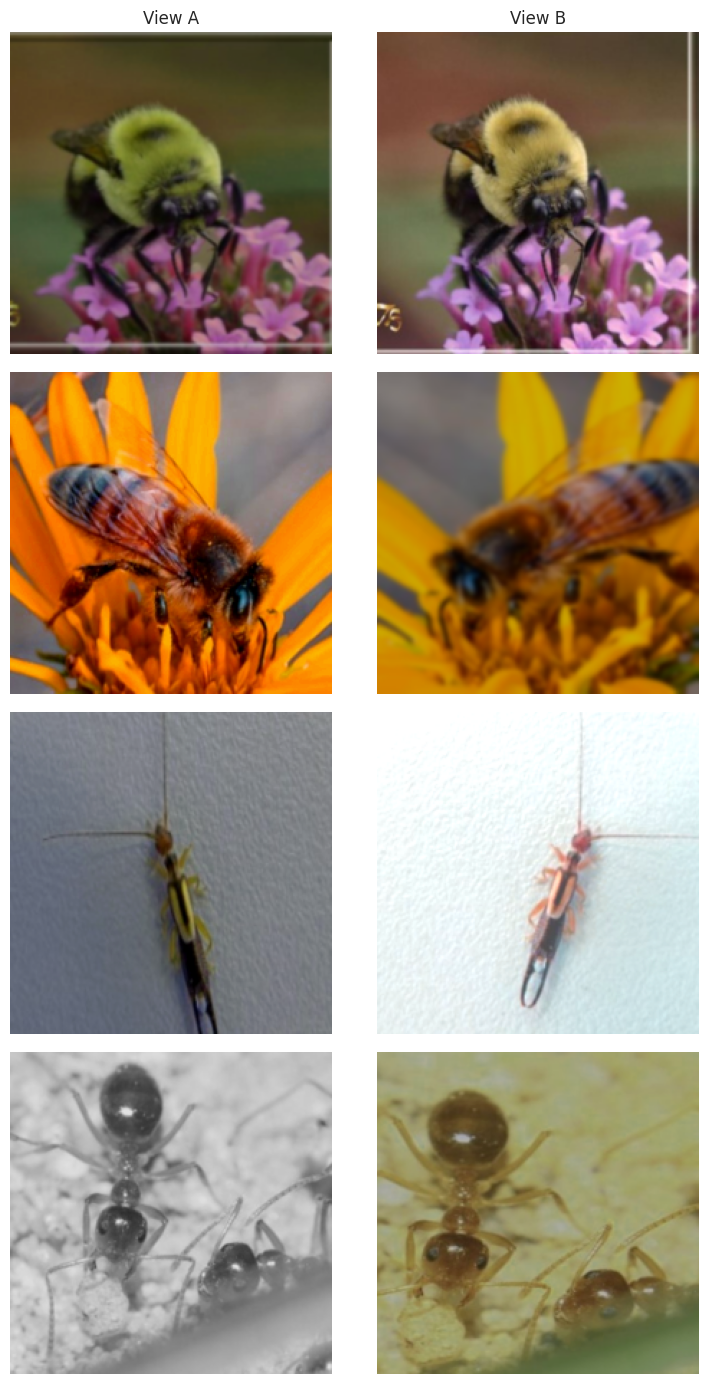

{'backbone_feature_dimension': 512, 'finite_loss': 2.817441940307617, 'finite_encoder_gradient': True}


/tmp/ipykernel_23/88286978.py:19: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at /pytorch/torch/csrc/autograd/generated/python_variable_methods.cpp:836.)
  print({"backbone_feature_dimension": feature_dim, "finite_loss": float(sanity_loss), "finite_encoder_gradient": True})


In [5]:
preview_dataset = ImagePairDataset(ssl_paths, build_simclr_transform(CONFIG))
mean, std = torch.tensor(IMAGENET_MEAN).view(3, 1, 1), torch.tensor(IMAGENET_STD).view(3, 1, 1)
fig, axes = plt.subplots(4, 2, figsize=(8, 14))
for row, index in enumerate(random.Random(323).sample(range(len(preview_dataset)), 4)):
    for column, view in enumerate(preview_dataset[index]):
        axes[row, column].imshow((view * std + mean).clamp(0, 1).permute(1, 2, 0)); axes[row, column].axis("off")
    axes[row, 0].set_ylabel(ssl_paths[index].name[:30], fontsize=8)
axes[0, 0].set_title("View A"); axes[0, 1].set_title("View B")
plt.tight_layout(); plt.show()

device = torch.device("cuda:0")
sanity_model, feature_dim = build_simclr_model(CONFIG, device)
sanity_a, sanity_b = next(iter(DataLoader(preview_dataset, batch_size=2, shuffle=False, drop_last=True)))
with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=cfg.amp):
    sanity_loss = nt_xent_loss(sanity_model(sanity_a.to(device)), sanity_model(sanity_b.to(device)), cfg.temperature)
assert torch.isfinite(sanity_loss), f"Non-finite preflight loss: {sanity_loss.item()}"
sanity_loss.backward()
assert any(parameter.grad is not None and torch.isfinite(parameter.grad).all() for parameter in sanity_model.encoder.parameters())
print({"backbone_feature_dimension": feature_dim, "finite_loss": float(sanity_loss), "finite_encoder_gradient": True})
del sanity_model
torch.cuda.empty_cache()


## Dual-GPU SimCLR Training

The launcher starts one process per T4 GPU. The implementation uses local in-batch negatives: gradient synchronization is global, while the 254 negative examples per anchor are local to each rank. The one-epoch warm-up is implemented per optimizer step before cosine decay.


In [6]:
import subprocess

subprocess.run([
    sys.executable, "-m", "torch.distributed.run", "--standalone", "--nproc_per_node=2",
    str(RUNNER),
], check=True)


Epoch 01/30 | loss=4.92928 | lr=3.00e-04


/usr/local/lib/python3.12/dist-packages/torch/distributed/c10d_logger.py:83: UserWarning: barrier(): using the device under current context. You can specify `device_id` in `init_process_group` to mute this warning.
  return func(*args, **kwargs)


Epoch 02/30 | loss=3.69755 | lr=2.99e-04
Epoch 03/30 | loss=2.97591 | lr=2.97e-04
Epoch 04/30 | loss=2.61602 | lr=2.92e-04
Epoch 05/30 | loss=2.33552 | lr=2.86e-04
Epoch 06/30 | loss=2.17030 | lr=2.79e-04
Epoch 07/30 | loss=2.02230 | lr=2.70e-04
Epoch 08/30 | loss=1.91761 | lr=2.60e-04
Epoch 09/30 | loss=1.87012 | lr=2.48e-04
Epoch 10/30 | loss=1.80678 | lr=2.35e-04
Epoch 11/30 | loss=1.75537 | lr=2.21e-04
Epoch 12/30 | loss=1.71667 | lr=2.07e-04
Epoch 13/30 | loss=1.67468 | lr=1.91e-04
Epoch 14/30 | loss=1.66099 | lr=1.76e-04
Epoch 15/30 | loss=1.63237 | lr=1.60e-04
Epoch 16/30 | loss=1.60210 | lr=1.44e-04
Epoch 17/30 | loss=1.58172 | lr=1.28e-04
Epoch 18/30 | loss=1.56133 | lr=1.12e-04
Epoch 19/30 | loss=1.54088 | lr=9.67e-05
Epoch 20/30 | loss=1.53820 | lr=8.21e-05
Epoch 21/30 | loss=1.51302 | lr=6.83e-05
Epoch 22/30 | loss=1.50475 | lr=5.55e-05
Epoch 23/30 | loss=1.49482 | lr=4.38e-05
Epoch 24/30 | loss=1.48256 | lr=3.33e-05
Epoch 25/30 | loss=1.48420 | lr=2.43e-05
Epoch 26/30 | lo

CompletedProcess(args=['/usr/bin/python3', '-m', 'torch.distributed.run', '--standalone', '--nproc_per_node=2', '/kaggle/working/partB_01a_simclr_yolo12m/train_simclr.py'], returncode=0)

## Training Curves And Checkpoint Handoff

The curves describe SSL optimization, not detection accuracy. `best_ssl.pt` is the lowest-loss checkpoint. The paired downstream notebook loads only `simclr_best_backbone_yolo12m.pt` into a fresh `yolo12m.yaml` backbone and checks `transfer_report.json`.


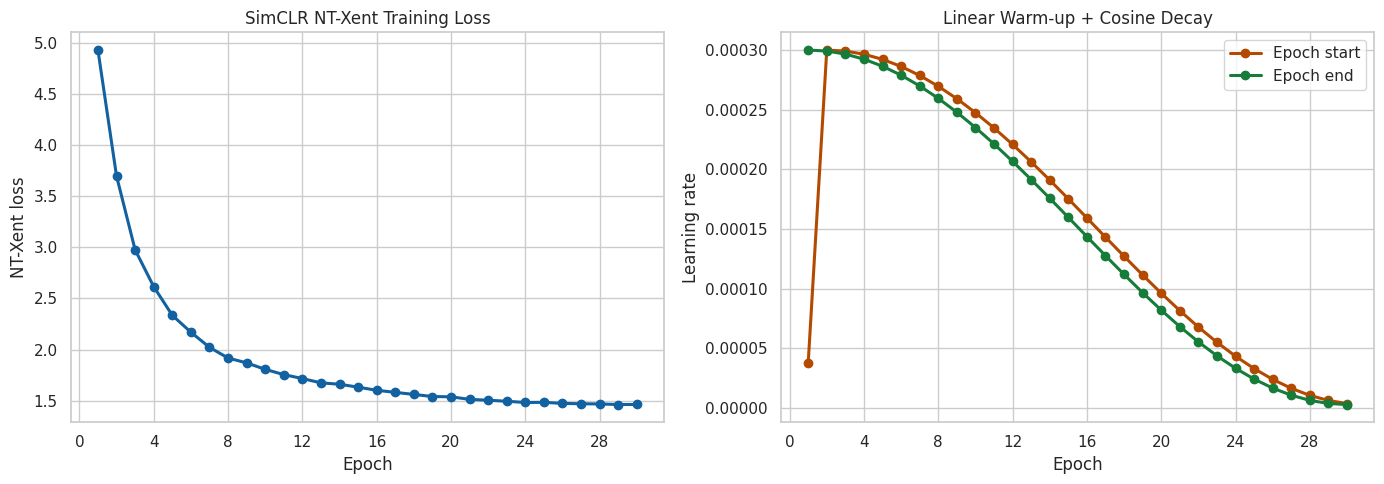

best SSL loss                                                              1.462665
best SSL checkpoint               /kaggle/working/partB_01a_simclr_yolo12m/best_...
backbone checkpoint               /kaggle/working/partB_01a_simclr_yolo12m/simcl...
detector-compatible checkpoint    /kaggle/working/partB_01a_simclr_yolo12m/simcl...
backbone coverage                                                            100.0%
dtype: object

In [7]:
from matplotlib.ticker import MaxNLocator

history = pd.read_csv(OUTPUT_DIR / "history.csv")
manifest = json.loads((OUTPUT_DIR / "run_manifest.json").read_text(encoding="utf-8"))
transfer_report = json.loads((OUTPUT_DIR / "transfer_report.json").read_text(encoding="utf-8"))
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].plot(history["epoch"], history["loss"], marker="o", linewidth=2.2, color="#1261A0")
axes[0].set(title="SimCLR NT-Xent Training Loss", xlabel="Epoch", ylabel="NT-Xent loss")
axes[0].xaxis.set_major_locator(MaxNLocator(integer=True))
axes[1].plot(history["epoch"], history["learning_rate_start"], marker="o", linewidth=2.2, color="#B34A00", label="Epoch start")
axes[1].plot(history["epoch"], history["learning_rate_end"], marker="o", linewidth=2.2, color="#167C3A", label="Epoch end")
axes[1].set(title="Linear Warm-up + Cosine Decay", xlabel="Epoch", ylabel="Learning rate")
axes[1].xaxis.set_major_locator(MaxNLocator(integer=True))
axes[1].legend()
plt.tight_layout(); plt.savefig(OUTPUT_DIR / "simclr_training_curves.png", dpi=180); plt.show()
pd.Series({"best SSL loss": manifest["best_loss"], "best SSL checkpoint": OUTPUT_DIR / "best_ssl.pt", "backbone checkpoint": OUTPUT_DIR / "simclr_best_backbone_yolo12m.pt", "detector-compatible checkpoint": OUTPUT_DIR / "simclr_best_backbone_yolo12m_detector.pt", "backbone coverage": f"{transfer_report['coverage']:.1%}"})


## Image-Only Representation Diagnostics

t-SNE and retrieval use a fixed sample from the SSL pool. They do not use labels and must not be interpreted as detection metrics.


In [8]:
import torch.nn.functional as F 

best_state = torch.load(
    OUTPUT_DIR / "best_ssl.pt",
    map_location="cpu",
    weights_only=False,
)

diagnostic_detector = YOLO(cfg.model_yaml).model
diagnostic_encoder = YOLOBackboneEncoder(diagnostic_detector)
diagnostic_encoder.load_state_dict(
    best_state["encoder_state_dict"],
    strict=True,
)
diagnostic_encoder = diagnostic_encoder.to(device).eval()

evaluation_transform = transforms.Compose([
    transforms.Resize(cfg.image_size + 32),
    transforms.CenterCrop(cfg.image_size),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])


class FeatureDataset(Dataset):
    def __init__(self, paths):
        self.paths = list(paths)

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, index):
        with Image.open(self.paths[index]) as image:
            return evaluation_transform(image.convert("RGB")), self.paths[index].name


diagnostic_paths = sorted(
    random.Random(cfg.seed).sample(
        ssl_paths,
        min(cfg.diagnostic_images, len(ssl_paths)),
    )
)
feature_loader = DataLoader(
    FeatureDataset(diagnostic_paths),
    batch_size=64,
    shuffle=False,
    num_workers=cfg.workers,
    pin_memory=True,
)

features, names = [], []
with torch.inference_mode():
    for images, batch_names in feature_loader:
        embeddings = diagnostic_encoder(
            images.to(device, non_blocking=True)
        )
        features.append(F.normalize(embeddings, dim=1).cpu())
        names.extend(batch_names)

feature_matrix = torch.cat(features)
assert torch.isfinite(feature_matrix).all()

print({
    "diagnostic_images": len(names),
    "feature_dimension": feature_matrix.shape[1],
    "mean_l2_norm": feature_matrix.norm(dim=1).mean().item(),
})


{'diagnostic_images': 500, 'feature_dimension': 512, 'mean_l2_norm': 1.0}


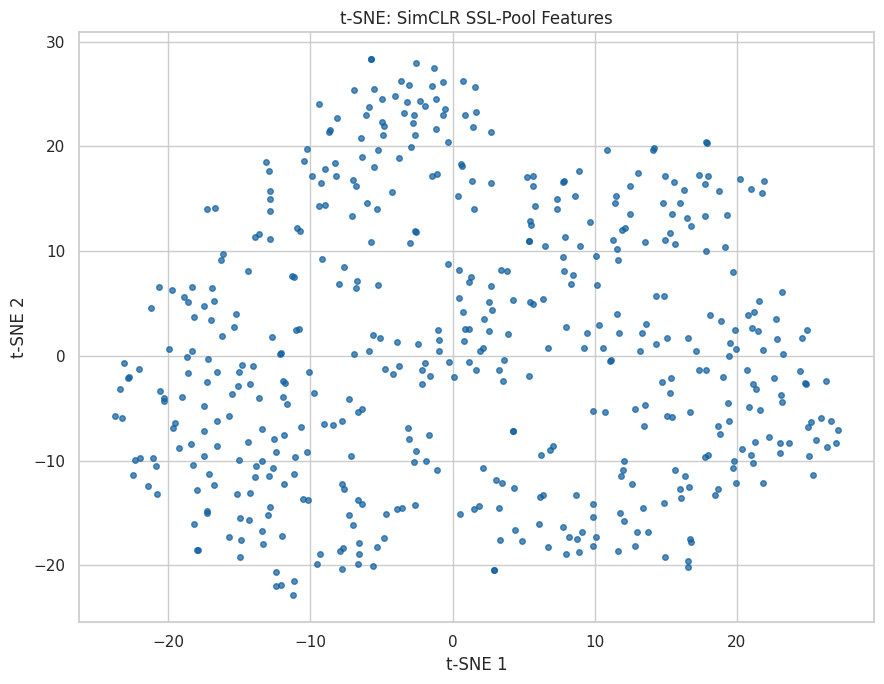

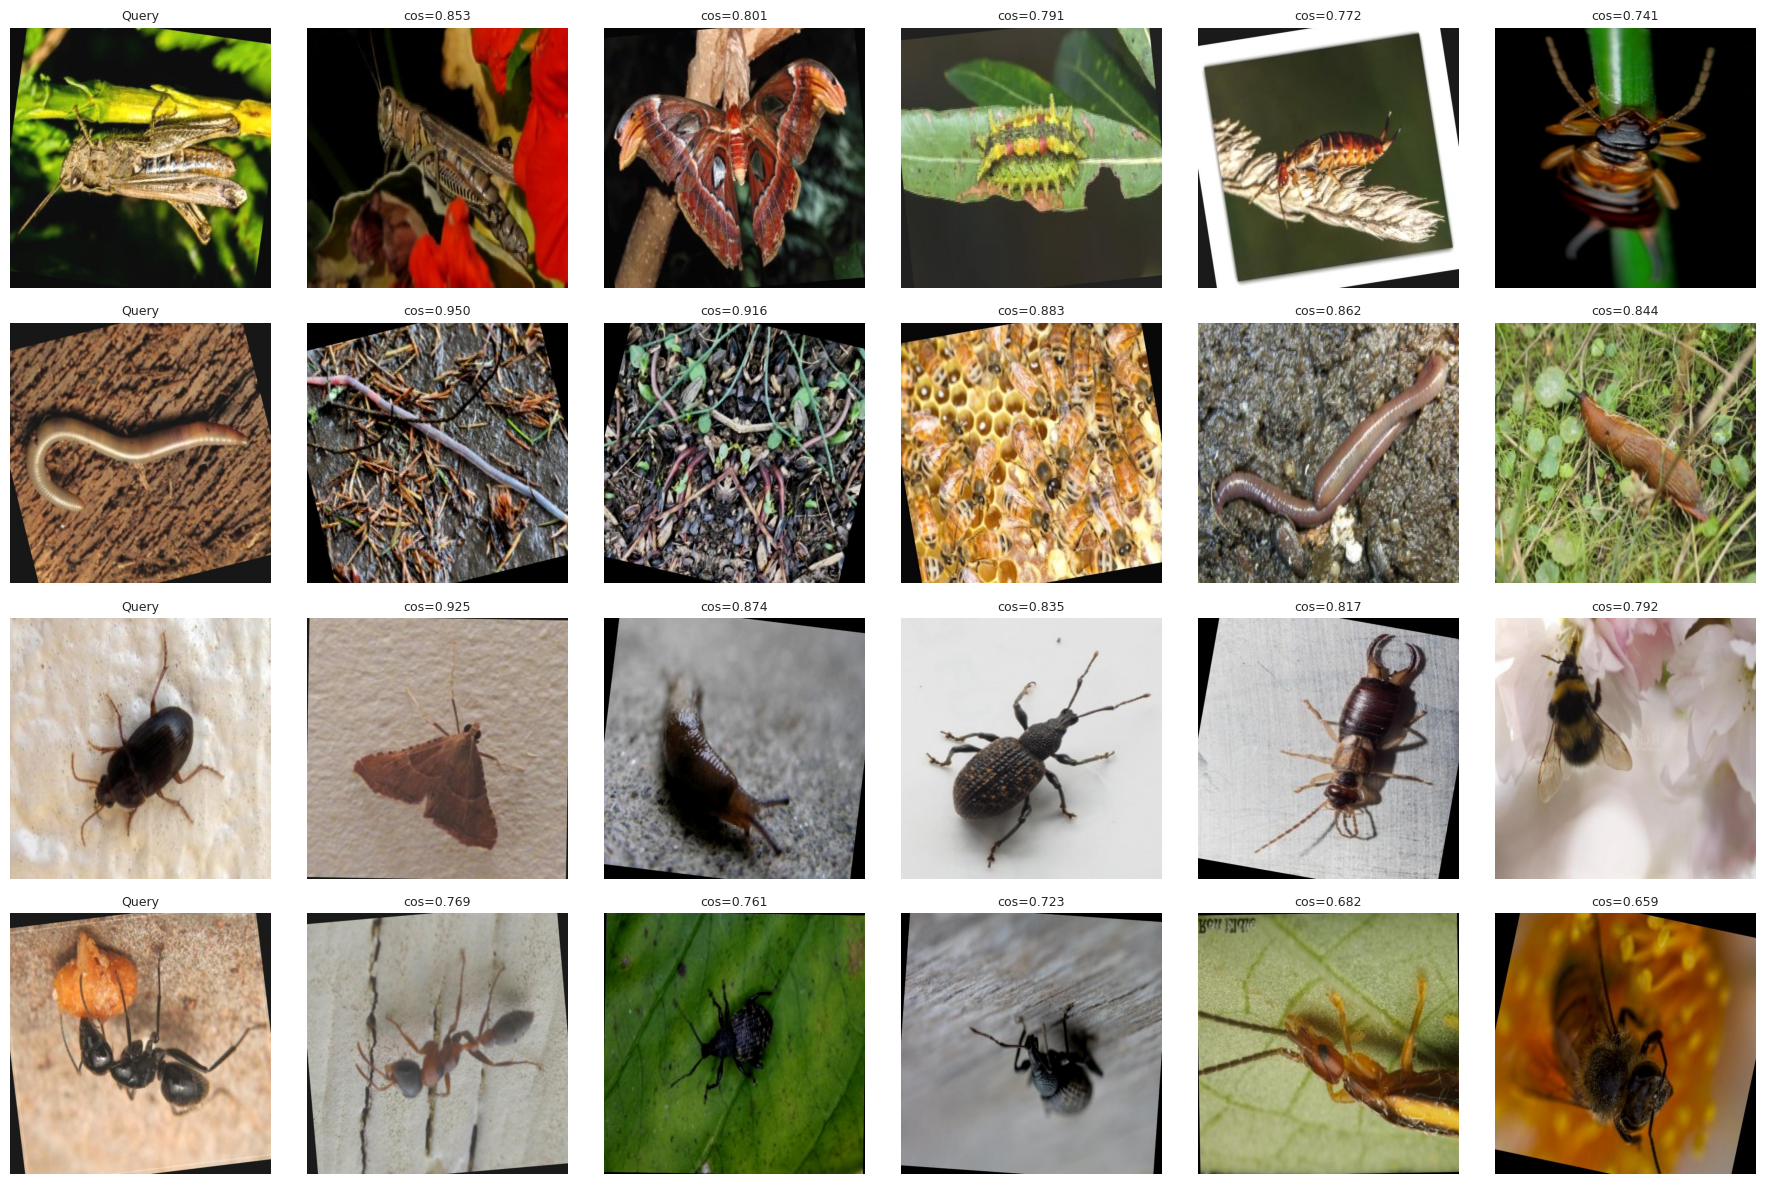

Interpret retrievals as image-level visual similarity only; Notebook 01b measures detection performance.


In [9]:
perplexity = min(30.0, max(5.0, (len(feature_matrix) - 1) / 3))
coordinates = TSNE(n_components=2, perplexity=perplexity, learning_rate="auto", init="pca", max_iter=1000, random_state=cfg.seed).fit_transform(feature_matrix.numpy())
fig, axis = plt.subplots(figsize=(9, 7))
axis.scatter(coordinates[:, 0], coordinates[:, 1], s=16, alpha=0.72, color="#1261A0")
axis.set(title="t-SNE: SimCLR SSL-Pool Features", xlabel="t-SNE 1", ylabel="t-SNE 2")
plt.tight_layout(); plt.savefig(OUTPUT_DIR / "simclr_tsne_ssl_pool.png", dpi=180); plt.show()
pd.DataFrame({"filename": names, "tsne_1": coordinates[:, 0], "tsne_2": coordinates[:, 1]}).to_csv(OUTPUT_DIR / "ssl_pool_embeddings_tsne.csv", index=False)

fig, axes = plt.subplots(cfg.retrieval_queries, cfg.retrieval_neighbors + 1, figsize=(3 * (cfg.retrieval_neighbors + 1), 3 * cfg.retrieval_queries))
rows = []
for row, query_index in enumerate(random.Random(cfg.seed).sample(range(len(diagnostic_paths)), cfg.retrieval_queries)):
    similarities = feature_matrix @ feature_matrix[query_index]
    neighbors = [index for index in torch.topk(similarities, k=cfg.retrieval_neighbors + 1).indices.tolist() if index != query_index][:cfg.retrieval_neighbors]
    for column, index in enumerate([query_index] + neighbors):
        with Image.open(diagnostic_paths[index]) as image: axes[row, column].imshow(image.convert("RGB"))
        axes[row, column].set_title("Query" if column == 0 else f"cos={similarities[index]:.3f}", fontsize=9); axes[row, column].axis("off")
        rows.append({"query": diagnostic_paths[query_index].name, "rank": column, "match": diagnostic_paths[index].name, "cosine_similarity": float(similarities[index])})
plt.tight_layout(); plt.savefig(OUTPUT_DIR / "simclr_nearest_neighbors.png", dpi=180); plt.show()
pd.DataFrame(rows).to_csv(OUTPUT_DIR / "simclr_nearest_neighbors.csv", index=False)
print("Interpret retrievals as image-level visual similarity only; Notebook 01b measures detection performance.")


## Publish

Publish the complete output directory as a Kaggle dataset. It includes the commented configuration JSON, modular DDP implementation, exact launcher, checkpoints, curves, diagnostics, and transfer report required by the downstream notebook.


In [10]:
print("Output directory:", OUTPUT_DIR)
for path in sorted(OUTPUT_DIR.rglob("*")):
    if path.is_file(): print(path.relative_to(OUTPUT_DIR))


Output directory: /kaggle/working/partB_01a_simclr_yolo12m
__pycache__/simclr_core.cpython-312.pyc
best_ssl.pt
history.csv
last_ssl.pt
run_manifest.json
simclr_best_backbone_yolo12m.pt
simclr_best_backbone_yolo12m_detector.pt
simclr_config.json
simclr_core.py
simclr_nearest_neighbors.csv
simclr_nearest_neighbors.png
simclr_training_curves.png
simclr_tsne_ssl_pool.png
ssl_pool_embeddings_tsne.csv
train_simclr.py
transfer_report.json
